# 데이터 전처리

In [ ]:
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# 1. 데이터 로드
df = pd.read_csv("hotel_preprocessed.csv", dtype={"agent": str})

# 2. 인코딩에서 제외할 컬럼 정의 (ID, split, 타깃 등)
EXCLUDE_COLS = ["source_row_id", "group_id", "split", "is_canceled"]

# 3. 실제 범주형 컬럼만 골라내기 (EXCLUDE_COLS에 포함된 컬럼 제외)
cat_cols = [c for c in df.select_dtypes(include=['object']).columns if c not in EXCLUDE_COLS]
print(f"인코딩 대상 범주형 컬럼 ({len(cat_cols)}개):", cat_cols)

## 수치형 컬럼 자동 추출 (EXCLUDE_COLS 및 범주형 제외)
num_cols = [c for c in df.columns if c not in cat_cols + EXCLUDE_COLS]

# 4. train / test 데이터셋 분리 (인코딩 전 원본 데이터 기준)
TARGET = "is_canceled"
train = df[df["split"] == "train"]
test = df[df["split"] == "test"]

X_train_raw, y_train = train.drop(columns=EXCLUDE_COLS + [TARGET]), train[TARGET]
X_test_raw, y_test = test.drop(columns=EXCLUDE_COLS + [TARGET]), test[TARGET]
groups_train = train["group_id"]

# 5. 사이킷런 ColumnTransformer 및 Pipeline 구축
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    
    ('onehot', OneHotEncoder(
        handle_unknown="ignore", 
        min_frequency=100, 
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), num_cols),
        ('cat', cat_transformer, cat_cols)
    ]
)

# 6. 전처리 실행 (fit은 train에만, transform은 train/test 모두에 적용)
X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

print(f"인코딩 후 X_train 형태: {X_train.shape}")
print(f"인코딩 후 X_test 형태: {X_test.shape}")

# cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)

# 교차검증·튜닝할 때 groups를 꼭 넣기
# cross_validate(model, X_train, y_train, cv=cv, groups=groups_train)
# search.fit(X_train, y_train, groups=groups_train)

인코딩 대상 범주형 컬럼 (10개): ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'agent', 'customer_type']
인코딩 후 X_train 형태: (95367, 179)
인코딩 후 X_test 형태: (23841, 179)


# XGBoost 분류 모델

## 모델 생성

In [24]:
# 필요한 모델 클래스 임포트
from xgboost import XGBClassifier

# 클래스 호출, 모델 생성
xgb = XGBClassifier(random_state=0)

## 모델 학습

In [25]:
xgb.fit(X_train, y_train)
print('학습 완료')

학습 완료


## 평가용 데이터에 대한 예측

In [26]:
pred_test_xgb = xgb.predict(X_test)
print(pred_test_xgb)

[0 0 0 ... 0 0 0]


## 모델 평가

In [27]:
# 필요한 함수 임포트
from sklearn.metrics import accuracy_score

# 평가용 데이터에 대한 성능 accuracy 측정
accuracy_xgb = accuracy_score(y_test, pred_test_xgb)

# 결과 확인
print(f'평가용 데이터에 대한 성능: {accuracy_xgb:.4f}')

평가용 데이터에 대한 성능: 0.8603


In [28]:
# 필요한 함수 임포트
from sklearn.metrics import classification_report

# 평가용 데이터에 대한 성능 accuracy 측정
cr_xgb = classification_report(y_test, pred_test_xgb)

# 결과 확인
print(f'평가용 데이터에 대한 성능: {cr_xgb}')

평가용 데이터에 대한 성능:               precision    recall  f1-score   support

           0       0.87      0.92      0.89     15002
           1       0.85      0.76      0.80      8839

    accuracy                           0.86     23841
   macro avg       0.86      0.84      0.85     23841
weighted avg       0.86      0.86      0.86     23841



# XGBoost 분류 모델 고도화

## GridSearchCV

In [37]:
# 필요한 클래스 임포트
from sklearn.model_selection import GridSearchCV

# 그룹 교차 검증 객체 생성
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)

# 성능 고도화 대상 모델 생성
xgb_base = XGBClassifier(
    random_state=0, 
    eval_metric='logloss',
    n_jobs=-1
)

# 최적화 할 매개 변수와 탐색 범위 설정
params = {
    'n_estimators': [100, 200],        # 트리의 개수
    'max_depth': [3, 5, 7],            # 트리의 최대 깊이 (과적합 방지)
    'learning_rate': [0.01, 0.1, 0.2], # 학습률 (Step Size)
    'subsample': [0.8, 1.0],           # 샘플링 비율
    'colsample_bytree': [0.8, 1.0]     # 특성 샘플링 비율
}

# 탐색 도구 생성
grid_xgb = GridSearchCV(
    estimator=xgb_base,
    param_grid=params,
    scoring='f1',       
    cv=cv,              # 위에서 정의한 StratifiedGroupKFold 적용
    n_jobs=-1,          
    verbose=1           
)

# 탐색 도구 학습 및 검증
grid_xgb.fit(X_train, y_train, groups=groups_train)
print('탐색 완료')

Fitting 5 folds for each of 72 candidates, totalling 360 fits
탐색 완료


In [38]:
# best 모델 추출
best_xgb = grid_xgb.best_estimator_
print(best_xgb)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=1.0, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.2, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=7, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=-1,
              num_parallel_tree=None, ...)


In [39]:
# 검증용 데이터에 대한 최적의 성능 확인
print(grid_xgb.best_score_)

0.8055751415154871


### 평가용 데이터를 이용한 예측

In [40]:
pred_test_grid_xgb = best_xgb.predict(X_test)

### 모델 평가

In [41]:
# 필요한 함수 임포트
from sklearn.metrics import accuracy_score

# 평가용 데이터에 대한 성능 accuracy 측정
accuracy_grid_xgb = accuracy_score(y_test, pred_test_grid_xgb)

# 결과 확인
print(f'평가용 데이터에 대한 성능: {accuracy_grid_xgb:.4f}')

평가용 데이터에 대한 성능: 0.8611


In [42]:
# 필요한 함수 임포트
from sklearn.metrics import classification_report

# 평가용 데이터에 대한 4가지 성능 측정
performance_xgb = classification_report(y_test, pred_test_grid_xgb)

# 결과 확인
print(f'고도화된 XGBoost 분류 모델의 평가용 데이터에 대한 4가지 성능: \n{performance_xgb}')

고도화된 XGBoost 분류 모델의 평가용 데이터에 대한 4가지 성능: 
              precision    recall  f1-score   support

           0       0.87      0.92      0.89     15002
           1       0.85      0.77      0.80      8839

    accuracy                           0.86     23841
   macro avg       0.86      0.84      0.85     23841
weighted avg       0.86      0.86      0.86     23841



## RandomizedSearchCV

In [ ]:
# 필요한 클래스 임포트
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV, cross_validate
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from xgboost import XGBClassifier
from scipy.stats import randint, uniform

# 그룹 교차 검증 객체 생성
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)

# 성능 고도화 대상 모델 생성
xgb_base = XGBClassifier(
    random_state=0, 
    eval_metric='logloss',
    n_jobs=-1
)

# 튜닝 전 기본 모델의 교차 검증 성능 확인 (groups 필수!)
cv_results = cross_validate(
    xgb_base, X_train, y_train, 
    cv=cv, 
    groups=groups_train, 
    scoring='f1'
)

# 최적화 할 매개 변수와 탐색 범위 설정
param_distributions = {
    'n_estimators': randint(100, 500),         # 100~500 사이의 무작위 정수
    'max_depth': randint(3, 10),               # 3~10 사이의 무작위 정수
    'learning_rate': uniform(0.01, 0.2),       # 0.01~0.21 사이의 무작위 실수
    'subsample': uniform(0.6, 0.4),            # 0.6~1.0 사이의 무작위 실수
    'colsample_bytree': uniform(0.6, 0.4)      # 0.6~1.0 사이의 무작위 실수
}

# 탐색 도구 생성
random_xgb = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_distributions,
    n_iter=20,          # 탐색할 조합 수
    scoring='f1',       # F1-Score 기준 최적화
    cv=cv,              # 위에서 정의한 StratifiedGroupKFold 적용
    random_state=42,
    n_jobs=-1,          
    verbose=1           
)

# 탐색 도구 학습 및 검증
random_xgb.fit(X_train, y_train, groups=groups_train)
print('탐색 완료')

Fitting 5 folds for each of 20 candidates, totalling 100 fits
탐색 완료


In [51]:
# best 모델 추출
best_random_xgb = random_xgb.best_estimator_
print(best_random_xgb)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=np.float64(0.6571467271687763), device=None,
              early_stopping_rounds=None, enable_categorical=True,
              eval_metric='logloss', feature_types=None, feature_weights=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None,
              learning_rate=np.float64(0.14017769458977059), max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=7, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=357, n_jobs=-1,
              num_parallel_tree=None, ...)


### 평가용 데이터를 이용한 예측

In [52]:
# 검증용 데이터에 대한 최적의 성능 확인
pred_test_random_xgb = best_random_xgb.predict(X_test)

### 모델 평가

In [53]:
# 필요한 함수 임포트
from sklearn.metrics import accuracy_score

# 평가용 데이터에 대한 성능 accuracy 측정
accuracy_random_xgb = accuracy_score(y_test, pred_test_random_xgb)

# 결과 확인
print(f'평가용 데이터에 대한 성능: {accuracy_random_xgb:.4f}')

평가용 데이터에 대한 성능: 0.8644


In [54]:
# 필요한 함수 임포트
from sklearn.metrics import classification_report

# 평가용 데이터에 대한 4가지 성능 측정
performance_random_xgb = classification_report(y_test, pred_test_random_xgb)

# 결과 확인
print(f'고도화된 XGBoost 분류 모델의 평가용 데이터에 대한 4가지 성능: \n{performance_random_xgb}')

고도화된 XGBoost 분류 모델의 평가용 데이터에 대한 4가지 성능: 
              precision    recall  f1-score   support

           0       0.87      0.92      0.90     15002
           1       0.85      0.77      0.81      8839

    accuracy                           0.86     23841
   macro avg       0.86      0.84      0.85     23841
weighted avg       0.86      0.86      0.86     23841



In [58]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import pandas as pd

# 1. 각 모델별 예측값 준비 (이미 앞서 학습 및 예측을 마쳤다고 가정)
# - 기본 모델: pred_test_xgb
# - GridSearchCV 모델: pred_test_grid_xgb
# - RandomizedSearchCV 모델: pred_test_random_xgb (만약 변수명이 다르다면 아래를 확인해주세요)

predictions = {
    "XGBoost GridSearchCV": pred_test_grid_xgb,
    "XGBoost RandomizedSearchCV": pred_test_random_xgb
}

results = []

# 2. 모델별로 4가지 성능 지표(Accuracy, Precision, Recall, F1-Score) 계산
for name, preds in predictions.items():
    # 전체 정확도(Accuracy)
    acc = accuracy_score(y_test, preds)
    
    # 정밀도, 재현율, F1-score (취소 클래스인 '1' 기준, 혹은 weighted/macro 평균 중 선택)
    # 보통 이진 분류에서는 양성 클래스(1) 기준 혹은 macro 평균을 많이 사용합니다. 여기서는 취소(1) 기준 지표와 macro 평균을 함께 정리합니다.
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, preds, average='binary', pos_label=1)
    
    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

# 3. 데이터프레임으로 보기 쉽게 변환
perf_df = pd.DataFrame(results)

# 소수점 4자리까지 예쁘게 정렬하여 출력
pd.set_option('display.max_columns', None)
print("=== 모델별 성능 지표 비교 ===")
display(perf_df.round(4))

=== 모델별 성능 지표 비교 ===


,Model,Accuracy,Precision,Recall,F1-Score
0,XGBoost GridSearchCV,0.8611,0.8454,0.7654,0.8034
1,XGBoost RandomizedSearchCV,0.8644,0.8514,0.7685,0.8078


In [59]:
import joblib

# 1. 최적 모델 추출 (이미 앞서 best_random_xgb에 담겨있지만 명확히 재확인)
best_random_xgb = random_xgb.best_estimator_

# 2. 저장할 파일 경로 설정 (원하시는 이름으로 지정 가능)
model_filename = "best_xgboost_randomized_model.pkl"

# 3. joblib을 이용해 모델 저장
joblib.dump(best_random_xgb, model_filename)

print(f"✅ 모델 저장 완료: '{model_filename}' 파일이 성공적으로 생성되었습니다!")

✅ 모델 저장 완료: 'best_xgboost_randomized_model.pkl' 파일이 성공적으로 생성되었습니다!


=== 모델별 ROC-AUC 점수 비교 ===
1. 기본 XGBoost 모델          : 0.9376
2. GridSearchCV 고도화 모델   : 0.9399
3. RandomizedSearchCV 고도화 모델: 0.9407


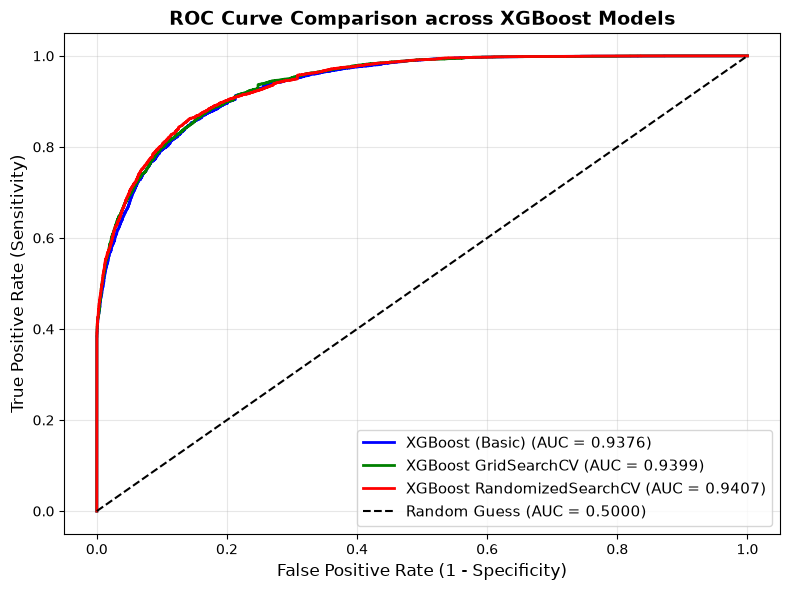

In [60]:
# 필요한 함수 및 라이브러리 임포트
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# 1. 3가지 모델에 대한 확률 예측값(Probability) 추출
# (양성 클래스인 '1'의 확률을 사용합니다: predict_proba[:, 1])
pred_proba_xgb = xgb.predict_proba(X_test)[:, 1]
pred_proba_grid = best_xgb.predict_proba(X_test)[:, 1]
pred_proba_random = best_random_xgb.predict_proba(X_test)[:, 1]

# 2. 모델별 ROC-AUC 점수 계산
auc_xgb = roc_auc_score(y_test, pred_proba_xgb)
auc_grid = roc_auc_score(y_test, pred_proba_grid)
auc_random = roc_auc_score(y_test, pred_proba_random)

# 3. 텍스트 결과 출력
print("=== 모델별 ROC-AUC 점수 비교 ===")
print(f"1. 기본 XGBoost 모델          : {auc_xgb:.4f}")
print(f"2. GridSearchCV 고도화 모델   : {auc_grid:.4f}")
print(f"3. RandomizedSearchCV 고도화 모델: {auc_random:.4f}")

# 4. ROC 커브 시각화
plt.figure(figsize=(8, 6))

# 각 모델의 False Positive Rate(FPR)와 True Positive Rate(TPR) 계산
models = [
    ("XGBoost (Basic)", pred_proba_xgb, auc_xgb, "blue"),
    ("XGBoost GridSearchCV", pred_proba_grid, auc_grid, "green"),
    ("XGBoost RandomizedSearchCV", pred_proba_random, auc_random, "red")
]

for name, proba, auc_score, color in models:
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.4f})", color=color, linewidth=2)

# 대각선 기준선 (랜덤 모델 성능: AUC 0.5)
plt.plot([0, 1], [0, 1], 'k--', label="Random Guess (AUC = 0.5000)")

# 그래프 레이아웃 설정
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=12)
plt.ylabel("True Positive Rate (Sensitivity)", fontsize=12)
plt.title("ROC Curve Comparison across XGBoost Models", fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [61]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, roc_auc_score
import pandas as pd

# 1. 3가지 모델별 예측값 및 확률값 준비
predictions = {
    "XGBoost (Basic)": pred_test_xgb,
    "XGBoost GridSearchCV": pred_test_grid_xgb,
    "XGBoost RandomizedSearchCV": pred_test_random_xgb
}

probabilities = {
    "XGBoost (Basic)": xgb.predict_proba(X_test)[:, 1],
    "XGBoost GridSearchCV": best_xgb.predict_proba(X_test)[:, 1],
    "XGBoost RandomizedSearchCV": best_random_xgb.predict_proba(X_test)[:, 1]
}

results = []

# 2. 모델별로 5가지 성능 지표(Accuracy, Precision, Recall, F1-Score, ROC-AUC) 계산
for name in predictions:
    preds = predictions[name]
    probs = probabilities[name]
    
    # 전체 정확도(Accuracy)
    acc = accuracy_score(y_test, preds)
    
    # 정밀도, 재현율, F1-score (취소 클래스인 '1' 기준)
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, preds, average='binary', pos_label=1)
    
    # ROC-AUC 점수 (확률값 기준)
    roc_auc = roc_auc_score(y_test, probs)
    
    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": roc_auc
    })

# 3. 데이터프레임으로 보기 쉽게 변환
perf_df = pd.DataFrame(results)

# 소수점 4자리까지 정렬하여 출력
pd.set_option('display.max_columns', None)
print("=== 전체 모델별 성능 지표 비교 (ROC-AUC 포함) ===")
display(perf_df.round(4))

=== 전체 모델별 성능 지표 비교 (ROC-AUC 포함) ===


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,XGBoost (Basic),0.8603,0.8456,0.7623,0.8018,0.9376
1,XGBoost GridSearchCV,0.8611,0.8454,0.7654,0.8034,0.9399
2,XGBoost RandomizedSearchCV,0.8644,0.8514,0.7685,0.8078,0.9407
